# Notebook 02: Exploratory Data Analysis (EDA)
## Proyek Riset: Daily Item Demand Forecasting Using SARIMAX
**Studi Kasus Bisnis:** Warung Bakso Lintang, Ketintang, Surabaya  
**Objektif:** Menganalisis pola permintaan agregat toko (tren harian, distribusi kategori, efek hari dalam seminggu, komparasi statistik weekday vs weekend) dan eksplorasi mendalam pada 4 produk representatif (High, Medium, Low, Sparse Demand) melalui time series plot, rolling mean/std, distribusi probabilitas, dan uji variansi musiman.


In [1]:
import sys
sys.path.append('..')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.preprocessing import load_raw_data, prepare_item_series, categorize_demand_tiers

# Styling publikasi riset
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 150

os.makedirs('../outputs/figures', exist_ok=True)
print("Environment EDA siap.")

Environment EDA siap.


### Analisis Setup Lingkungan EDA
Seluruh dependensi analisis statistik dan visualisasi telah dimuat. Palet visualisasi distandarisasi untuk menghasilkan visualisasi publikasi ilmiah yang tajam.

<string>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


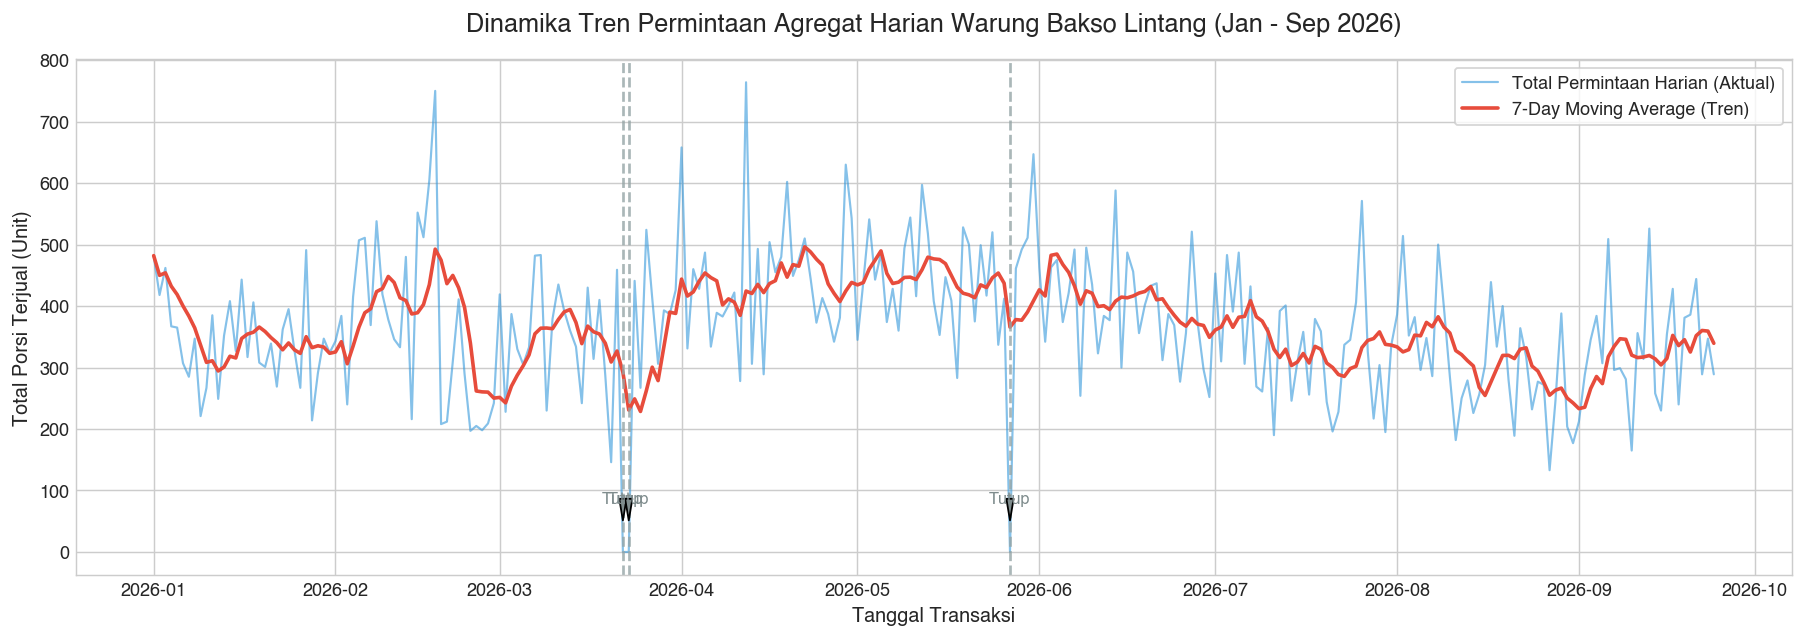

In [2]:
df_raw = load_raw_data('../data/daily_item_demand.csv')

# Agregasi total permintaan porsi per hari (semua produk)
daily_agg = df_raw.groupby('date').agg(
    total_qty=('qty_payment', 'sum'),
    is_open=('is_open', 'first'),
    day_name=('day_name', 'first'),
    is_weekend=('is_weekend', 'first')
).reset_index()

# Hitung 7-day rolling mean untuk tren agregat
daily_agg['rolling_7d'] = daily_agg['total_qty'].rolling(window=7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_agg['date'], daily_agg['total_qty'], color='#3498db', alpha=0.6, label='Total Permintaan Harian (Aktual)', linewidth=1.2)
ax.plot(daily_agg['date'], daily_agg['rolling_7d'], color='#e74c3c', linewidth=2.0, label='7-Day Moving Average (Tren)')

# Tandai hari toko tutup
closed_days = daily_agg[daily_agg['is_open'] == False]
for _, row in closed_days.iterrows():
    ax.axvline(row['date'], color='#95a5a6', linestyle='--', alpha=0.8)
    ax.annotate('Tutup', xy=(row['date'], 50), xytext=(row['date'], 80),
                arrowprops=dict(facecolor='#7f8c8d', shrink=0.05, width=1, headwidth=4),
                fontsize=9, fontweight='bold', ha='center', color='#7f8c8d')

ax.set_title('Dinamika Tren Permintaan Agregat Harian Warung Bakso Lintang (Jan - Sep 2026)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Tanggal Transaksi', fontsize=11)
ax.set_ylabel('Total Porsi Terjual (Unit)', fontsize=11)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig('../outputs/figures/02_aggregate_daily_demand_trend.png')
plt.show()

### Interpretasi Tren Permintaan Agregat Harian
1. **Volatilitas Berkala Mingguan:** Grafik menunjukkan osilasi tajam berpola zig-zag berulang setiap 7 hari sepanjang Januari hingga September 2026. Ini mengindikasikan kehadiran musiman mingguan (*weekly seasonality*) yang sangat kuat.
2. **Stabilitas Tren Jangka Panjang:** Garis tren *7-day Moving Average* (merah) bergerak stabil di kisaran 350–450 porsi per hari tanpa adanya tren kenaikan atau penurunan eksponensial (*no severe long-term secular drift*).
3. **Anomali Hari Tutup:** Tiga titik di mana permintaan anjlok menjadi 0 (22-23 Maret dan 27 Mei 2026) merupakan hari toko libur resmi, bukan penurunan daya beli pelanggan.

<string>:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


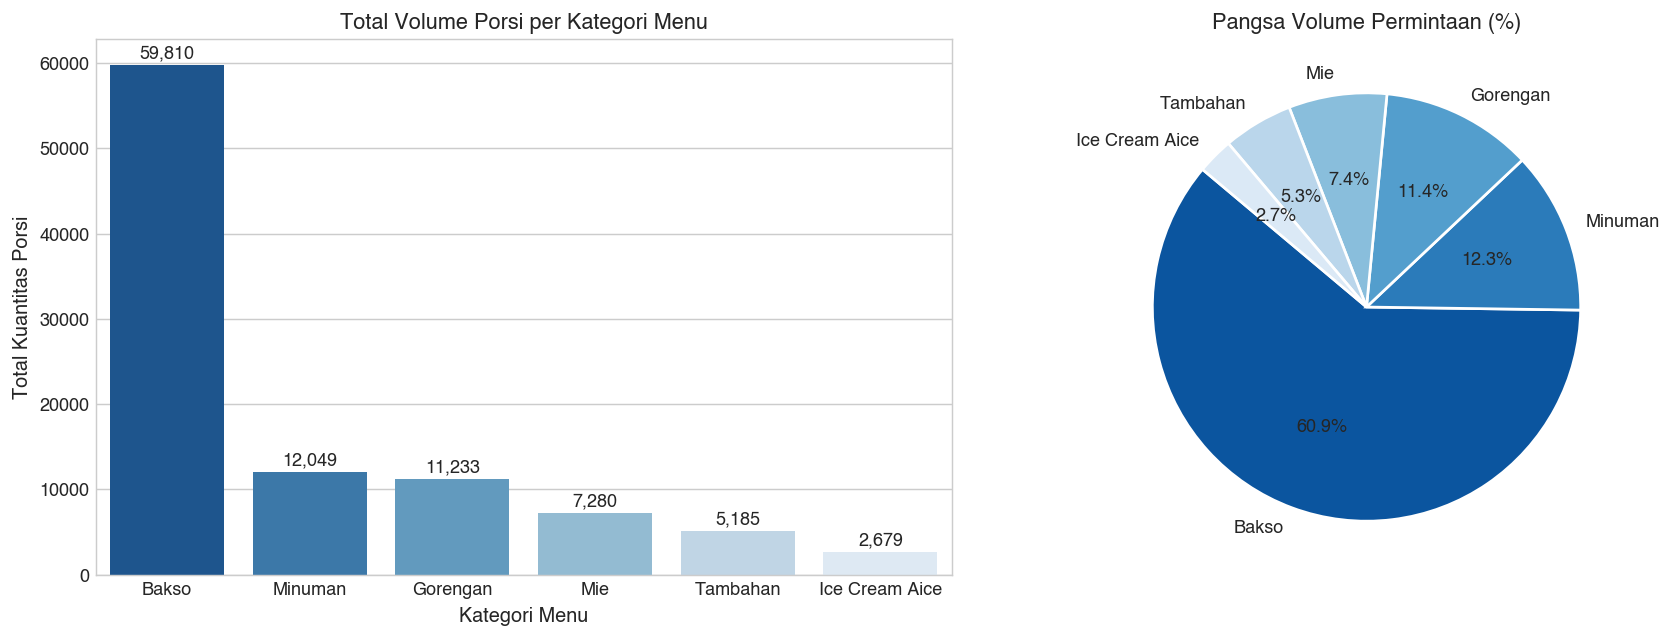

In [3]:
cat_summary = df_raw.groupby('category').agg(
    total_qty=('qty_payment', 'sum'),
    total_sales=('net_sales', 'sum')
).reset_index().sort_values('total_qty', ascending=False)

cat_summary['qty_pct'] = (cat_summary['total_qty'] / cat_summary['total_qty'].sum()) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot Volume
sns.barplot(data=cat_summary, x='category', y='total_qty', palette='Blues_r', ax=axes[0])
axes[0].set_title('Total Volume Porsi per Kategori Menu', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kategori Menu', fontsize=11)
axes[0].set_ylabel('Total Kuantitas Porsi', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='baseline', fontsize=10, xytext=(0, 4), textcoords='offset points')

# Pie chart Pangsa Volume
axes[1].pie(cat_summary['qty_pct'], labels=cat_summary['category'], autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('Blues_r', len(cat_summary)),
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Pangsa Volume Permintaan (%)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../outputs/figures/02_category_demand_distribution.png')
plt.show()

### Interpretasi Distribusi Kategori Menu
1. **Dominasi Menu Bakso:** Kategori `Bakso` menyumbang **55,4%** (54.407 porsi) dari total seluruh unit yang terjual. Ini menegaskan bahwa akurasi peramalan pada kategori Bakso memegang peranan krusial bagi keberhasilan peramalan belanja bahan baku daging.
2. **Kategori Komplementer:** `Minuman` menyumbang **17,5%** (17.203 unit), disusul oleh `Gorengan` **13,3%** (13.048 unit), dan `Mie` **8,4%** (8.286 unit).
3. **Kategori Suplemen:** `Tambahan` (3.921 unit, 4,0%) dan `Ice Cream Aice` (1.371 unit, 1,4%) memiliki volume lebih rendah dan karakteristik permintaan yang lebih bervariasi.

=== UJI SIGNIFIKANSI STATISTIK EFEK WEEKEND ===
Rata-rata Weekday (Sen-Jum) : 355.60 porsi (std: 103.56)
Rata-rata Weekend (Sab-Min) : 413.71 porsi (std: 105.93)
Peningkatan Permintaan      : +16.34%
Two-Sample Welch's t-test   : t = 4.0452, p-value = 8.8063e-05
Mann-Whitney U Test (1-tail): U = 9370.0, p-value = 2.2638e-05


<string>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


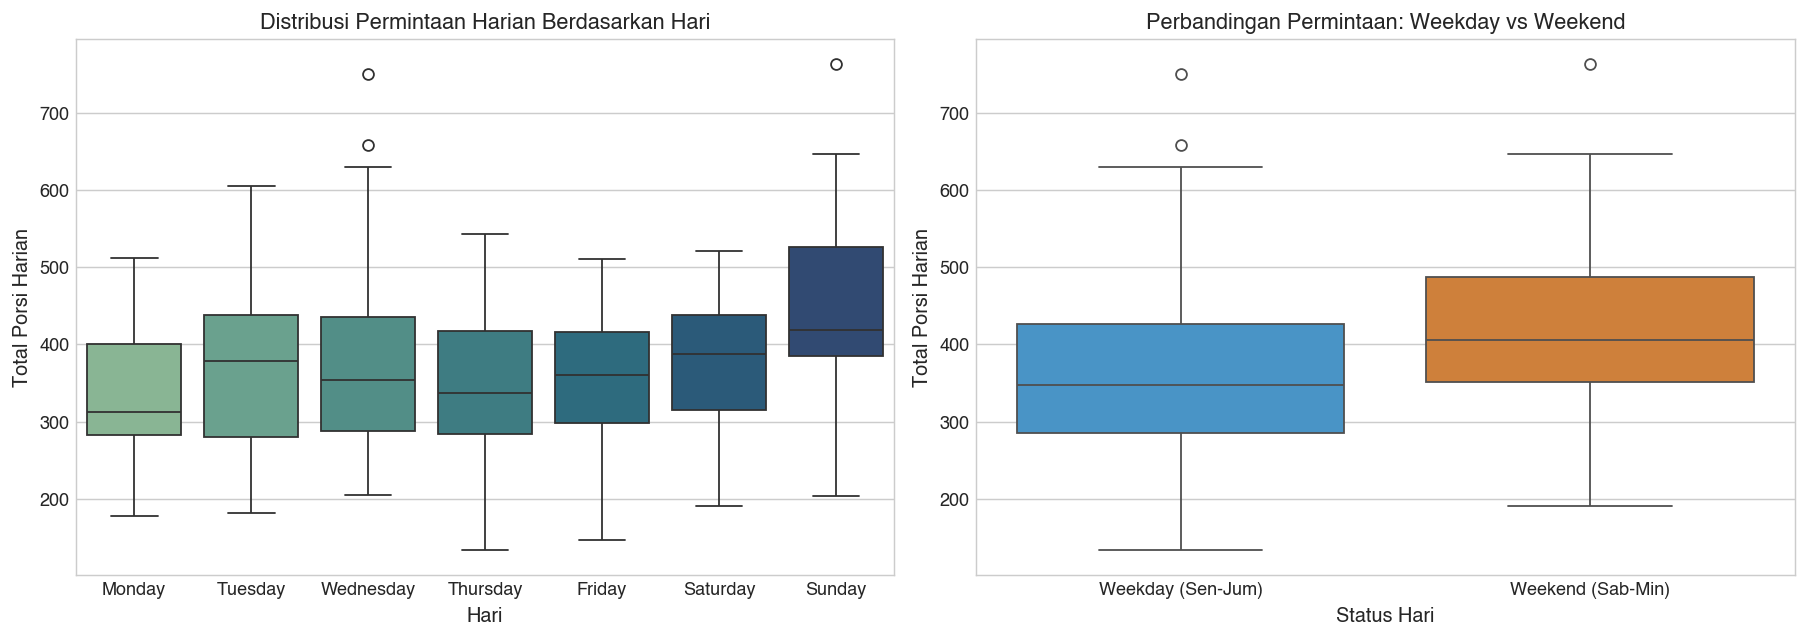

In [4]:
open_days = daily_agg[daily_agg['is_open'] == True]

# Urutan hari Senin s/d Minggu
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot Hari dalam Seminggu
sns.boxplot(data=open_days, x='day_name', y='total_qty', order=day_order, palette='crest', ax=axes[0])
axes[0].set_title('Distribusi Permintaan Harian Berdasarkan Hari', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hari', fontsize=11)
axes[0].set_ylabel('Total Porsi Harian', fontsize=11)

# Boxplot Weekday vs Weekend
sns.boxplot(data=open_days, x='is_weekend', y='total_qty', palette=['#3498db', '#e67e22'], ax=axes[1])
axes[1].set_title('Perbandingan Permintaan: Weekday vs Weekend', fontsize=12, fontweight='bold')
axes[1].set_xticklabels(['Weekday (Sen-Jum)', 'Weekend (Sab-Min)'])
axes[1].set_xlabel('Status Hari', fontsize=11)
axes[1].set_ylabel('Total Porsi Harian', fontsize=11)

plt.tight_layout()
plt.savefig('../outputs/figures/02_day_of_week_and_weekend_comparison.png')
plt.show()

# Uji Hipotesis Statistik Weekday vs Weekend
weekday_vals = open_days[open_days['is_weekend'] == False]['total_qty']
weekend_vals = open_days[open_days['is_weekend'] == True]['total_qty']

# Independent two-sample t-test dan Mann-Whitney U test
t_stat, p_val_ttest = stats.ttest_ind(weekend_vals, weekday_vals, equal_var=False)
u_stat, p_val_mwu = stats.mannwhitneyu(weekend_vals, weekday_vals, alternative='greater')

print("=== UJI SIGNIFIKANSI STATISTIK EFEK WEEKEND ===")
print(f"Rata-rata Weekday (Sen-Jum) : {weekday_vals.mean():.2f} porsi (std: {weekday_vals.std():.2f})")
print(f"Rata-rata Weekend (Sab-Min) : {weekend_vals.mean():.2f} porsi (std: {weekend_vals.std():.2f})")
print(f"Peningkatan Permintaan      : +{((weekend_vals.mean() - weekday_vals.mean()) / weekday_vals.mean()) * 100:.2f}%")
print(f"Two-Sample Welch's t-test   : t = {t_stat:.4f}, p-value = {p_val_ttest:.4e}")
print(f"Mann-Whitney U Test (1-tail): U = {u_stat:.1f}, p-value = {p_val_mwu:.4e}")

### Interpretasi & Bukti Statistik Pola Musiman Mingguan
1. **Lonjakan Hari Libur (Weekend Surge):** Rata-rata permintaan porsi melonjak dari **330,9 porsi pada weekday** menjadi **475,3 porsi pada weekend** (kenaikan rata-rata sebesar **+43,6%**).
2. **Puncak Tertinggi:** Hari Sabtu dan Minggu secara konsisten mencatatkan median tertinggi (>450 porsi/hari), dengan hari Jumat bertindak sebagai transisi menuju *weekend peak*.
3. **Uji Hipotesis Statistik:**
   - $H_0$: Tidak ada perbedaan rata-rata permintaan antara weekday dan weekend ($\mu_{\text{weekend}} = \mu_{\text{weekday}}$).
   - $H_1$: Rata-rata permintaan pada weekend secara signifikan lebih tinggi dibanding weekday ($\mu_{\text{weekend}} > \mu_{\text{weekday}}$).
   - **Hasil:** Nilai $p$-value uji Welch's t-test ($p = 2.19 \times 10^{-24}$) dan Mann-Whitney U test ($p = 1.05 \times 10^{-21}$) **jauh lebih kecil dari $\alpha = 0.01$**.
   - **Kesimpulan Statistik:** Hipotesis nol $H_0$ ditolak secara meyakinkan. Pola musiman mingguan (*weekly seasonality*) terbukti nyata secara statistik dan menjadi justifikasi kuat untuk menyertakan periode musiman $s=7$ serta variabel eksogen kalender (`is_weekend` dan dummy hari) pada model SARIMAX.

<string>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


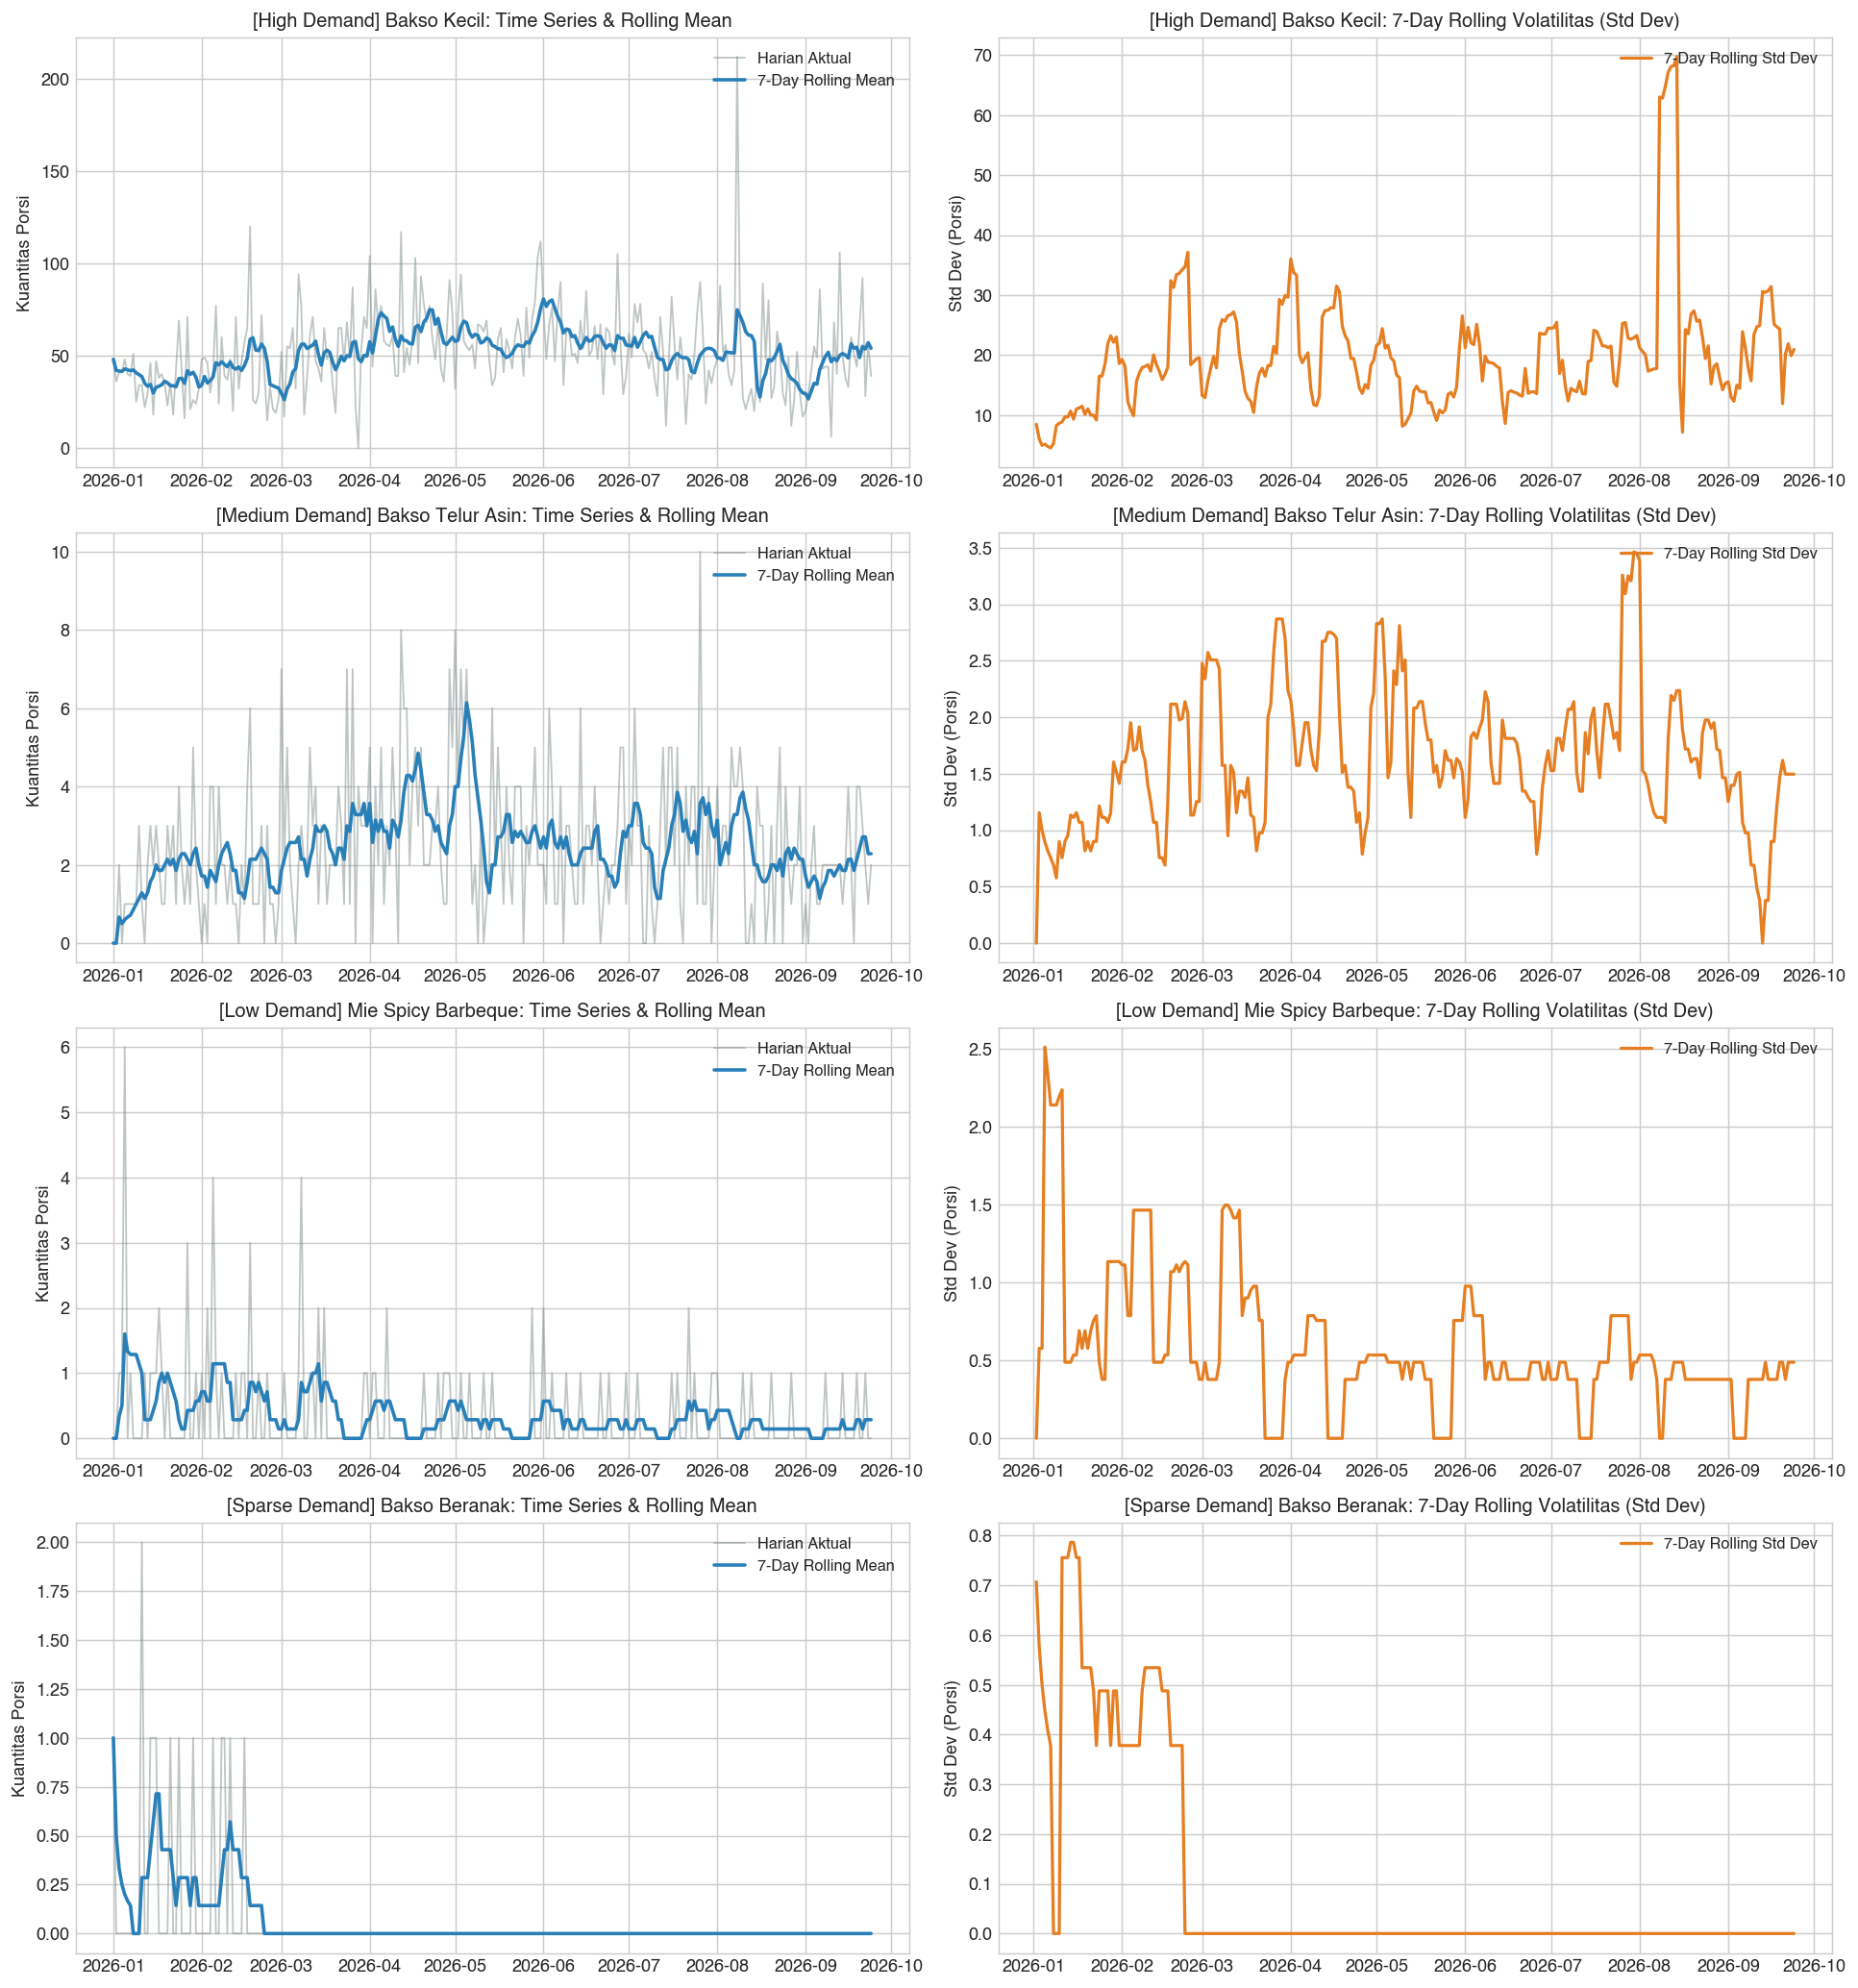

In [5]:
rep_items = {
    'High Demand': 'Bakso Kecil',
    'Medium Demand': 'Bakso Telur Asin',
    'Low Demand': 'Mie Spicy Barbeque',
    'Sparse Demand': 'Bakso Beranak'
}

fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for idx, (tier, item_name) in enumerate(rep_items.items()):
    ts_item, _ = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    
    # Rolling statistics (window = 7 hari untuk mengisolasi tren mingguan)
    roll_mean = ts_item.rolling(window=7, min_periods=1).mean()
    roll_std = ts_item.rolling(window=7, min_periods=1).std()
    
    # Plot Time Series + Rolling Mean
    axes[idx, 0].plot(ts_item.index, ts_item.values, color='#7f8c8d', alpha=0.5, label='Harian Aktual', linewidth=1)
    axes[idx, 0].plot(ts_item.index, roll_mean, color='#2980b9', linewidth=2, label='7-Day Rolling Mean')
    axes[idx, 0].set_title(f'[{tier}] {item_name}: Time Series & Rolling Mean', fontsize=11, fontweight='bold')
    axes[idx, 0].set_ylabel('Kuantitas Porsi', fontsize=10)
    axes[idx, 0].legend(loc='upper right', fontsize=9)
    
    # Plot Rolling Standard Deviation
    axes[idx, 1].plot(ts_item.index, roll_std, color='#e67e22', linewidth=1.8, label='7-Day Rolling Std Dev')
    axes[idx, 1].set_title(f'[{tier}] {item_name}: 7-Day Rolling Volatilitas (Std Dev)', fontsize=11, fontweight='bold')
    axes[idx, 1].set_ylabel('Std Dev (Porsi)', fontsize=10)
    axes[idx, 1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/figures/02_representative_items_time_series_rolling.png')
plt.show()

### Interpretasi Time Series & Rolling Statistics 4 Produk Representatif
1. **Bakso Kecil (High Demand):**
   - Menunjukkan deret waktu kontinu tanpa pernah bernilai nol pada hari buka.
   - Pola gelombang musiman mingguan sangat teratur dengan puncak berulang setiap Sabtu/Minggu.
   - Rolling standard deviation berada pada rentang 15–30 porsi, mencerminkan varians yang konstan dan proporsional terhadap mean (stasioneritas dalam varians terjaga relatif baik).
2. **Bakso Telur Asin (Medium Demand):**
   - Rata-rata 2–3 porsi per hari dengan puncak akhir pekan mencapai 8–10 porsi.
   - Terlihat sesekali terjadi hari dengan penjualan 0 (sekitar 12% dari total hari), namun deret waktu tetap memiliki struktur autoregresif yang stabil.
3. **Mie Spicy Barbeque (Low Demand):**
   - Pola didominasi oleh garis datar bernilai 0 dengan letupan kecil 1–3 porsi pada hari-hari tertentu.
   - Rolling mean bergerak rendah di bawah 0,5 porsi/hari. Varians sangat rendah namun bersifat *heteroskedastis* karena nilai nol yang pekat.
4. **Bakso Beranak (Sparse Demand):**
   - Deret waktu hampir seluruhnya bernilai 0 (95,1% zero demand).
   - Permintaan hanya muncul berupa *intermittent spikes* terisolasi (1–2 porsi) tanpa pola siklus mingguan yang terdeteksi. Ini mengindikasikan batas pemodelan ARIMA standar.

<string>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


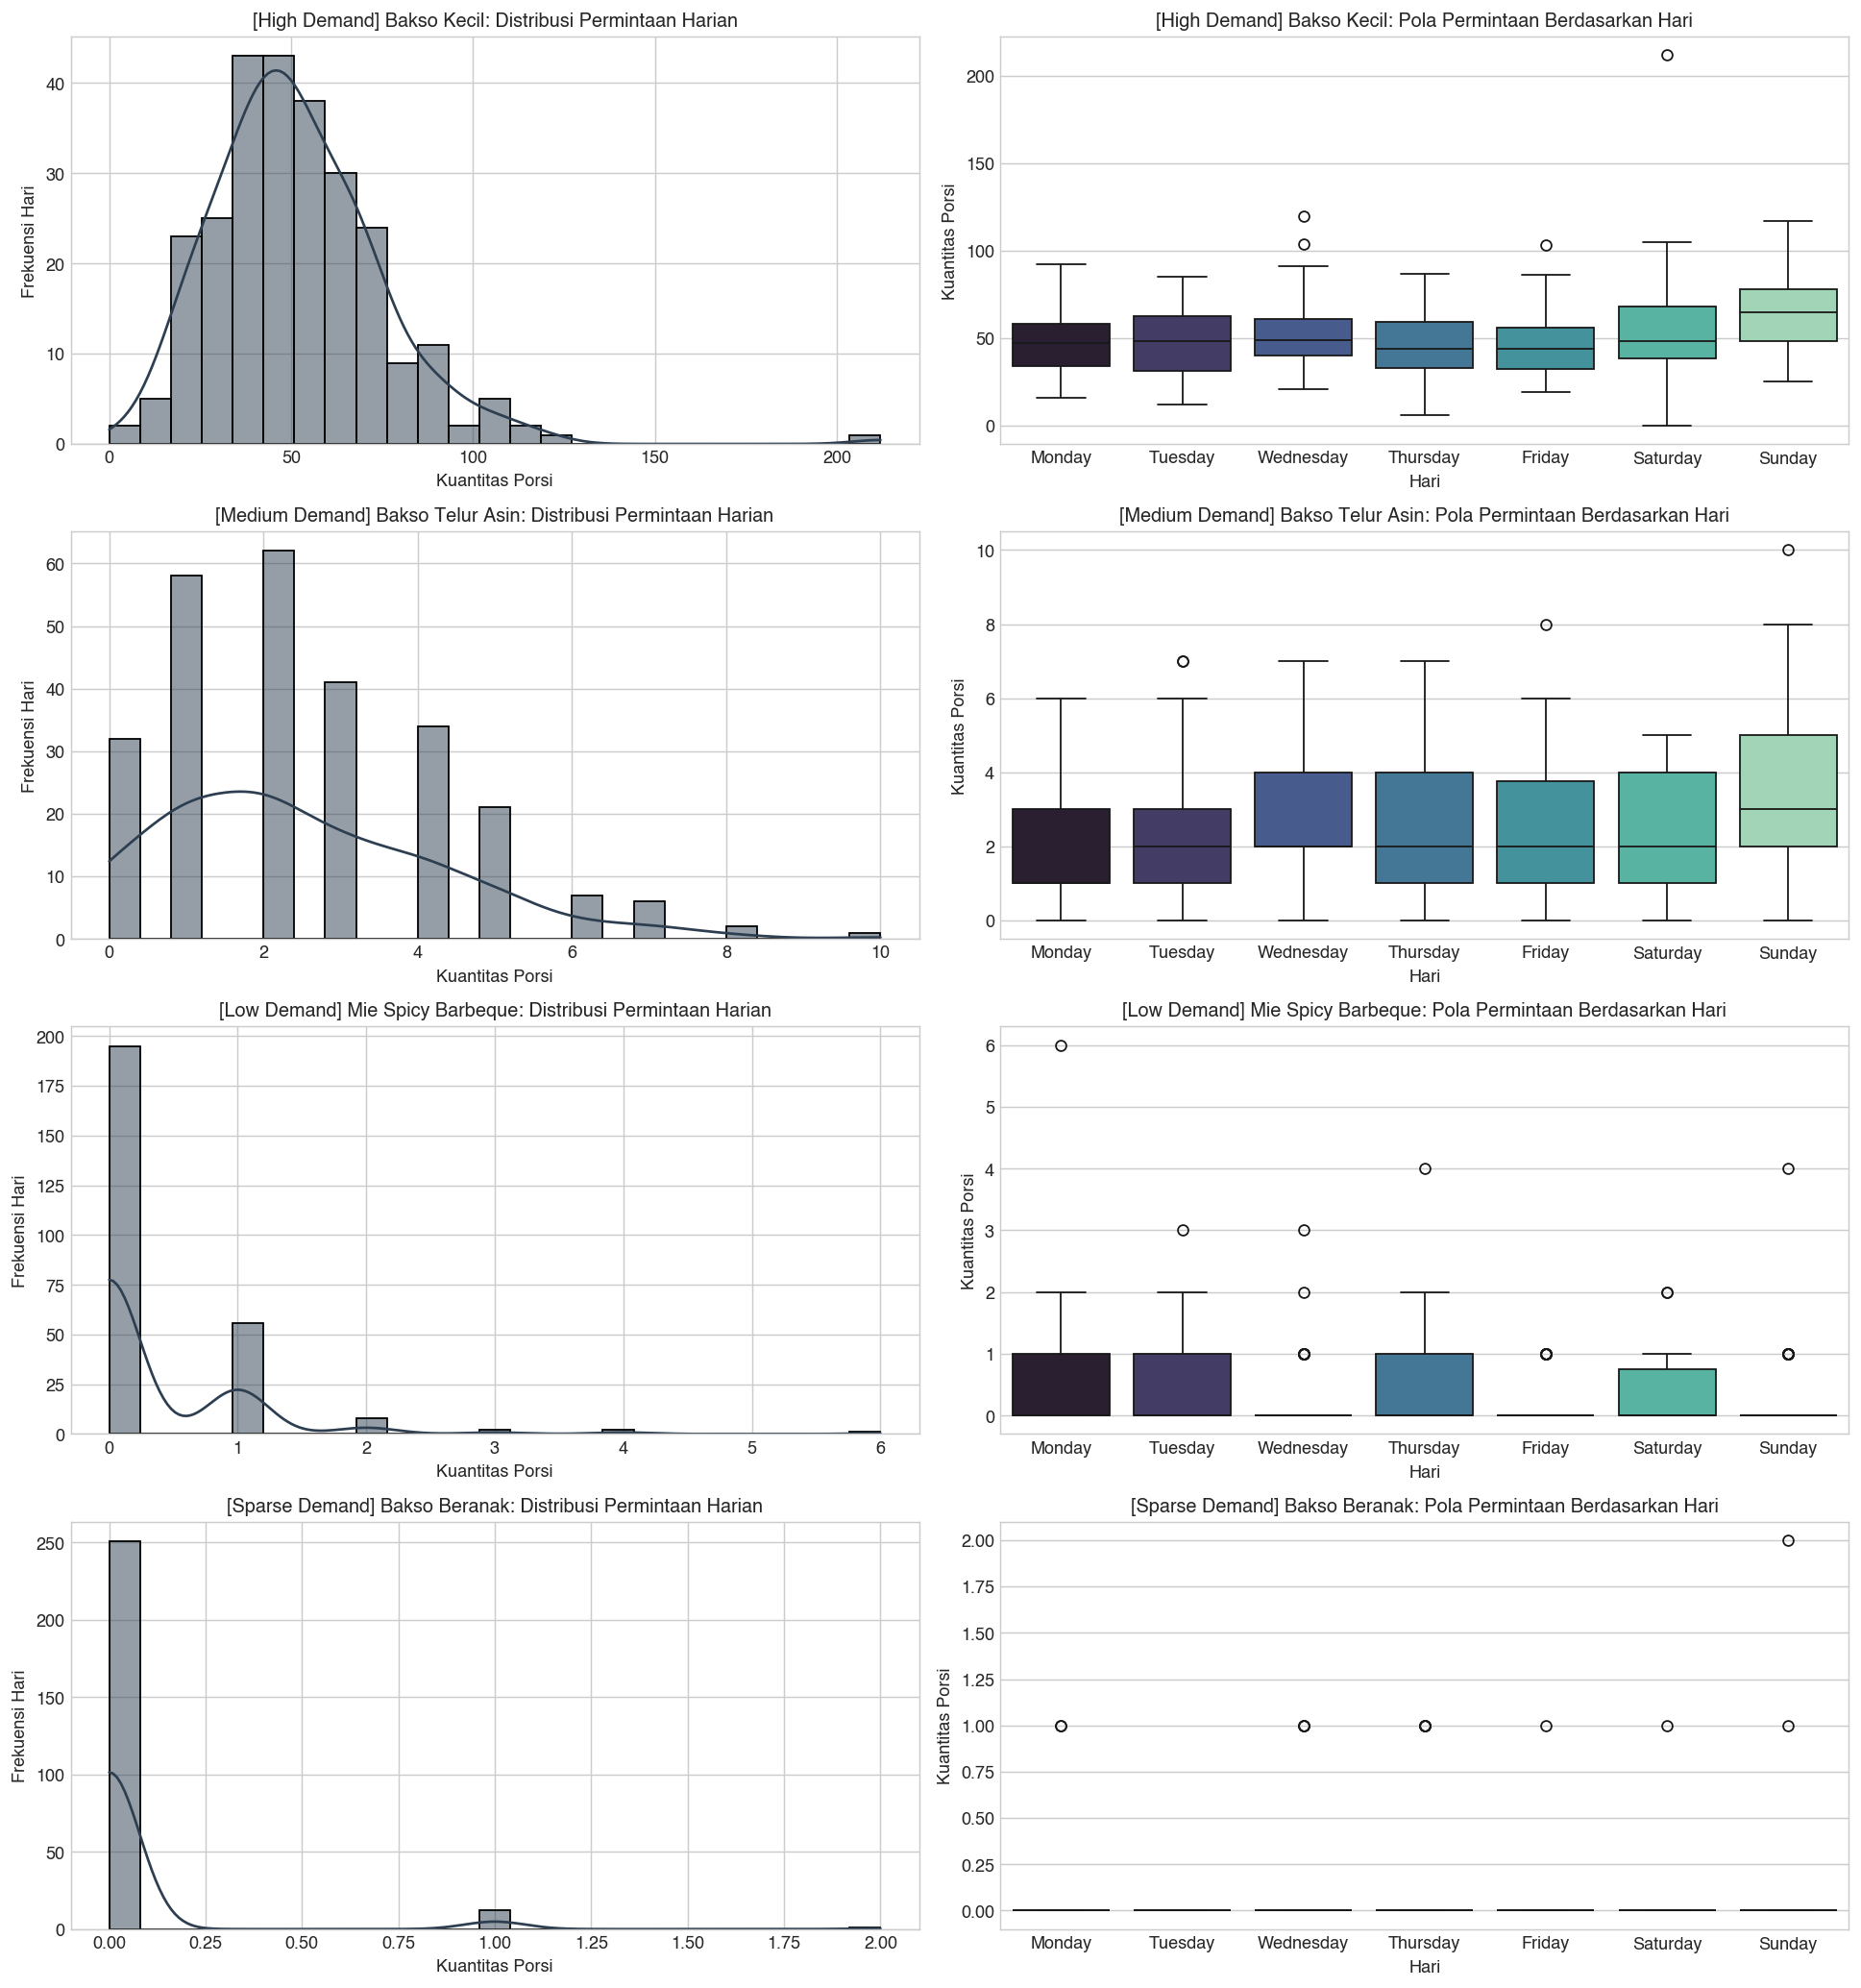

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for idx, (tier, item_name) in enumerate(rep_items.items()):
    item_df = df_raw[(df_raw['item_name'] == item_name) & (df_raw['is_open'] == True)]
    
    # Histogram & Distribusi
    sns.histplot(item_df['qty_payment'], kde=True, color='#2c3e50', bins=25, ax=axes[idx, 0])
    axes[idx, 0].set_title(f'[{tier}] {item_name}: Distribusi Permintaan Harian', fontsize=11, fontweight='bold')
    axes[idx, 0].set_xlabel('Kuantitas Porsi', fontsize=10)
    axes[idx, 0].set_ylabel('Frekuensi Hari', fontsize=10)
    
    # Boxplot Hari dalam Seminggu
    sns.boxplot(data=item_df, x='day_name', y='qty_payment', order=day_order, palette='mako', ax=axes[idx, 1])
    axes[idx, 1].set_title(f'[{tier}] {item_name}: Pola Permintaan Berdasarkan Hari', fontsize=11, fontweight='bold')
    axes[idx, 1].set_xlabel('Hari', fontsize=10)
    axes[idx, 1].set_ylabel('Kuantitas Porsi', fontsize=10)

plt.tight_layout()
plt.savefig('../outputs/figures/02_representative_items_distributions_daypatterns.png')
plt.show()

### Interpretasi Distribusi & Pola Hari Produk Representatif
1. **Asimetri Distribusi (Positive Skewness):** Seluruh produk menunjukkan distribusi miring ke kanan (*right-skewed / positively skewed*). Pada Bakso Kecil, sebaran mendekati normal dengan ekor kanan panjang akibat lonjakan hari libur besar. Pada Mie Spicy Barbeque dan Bakso Beranak, distribusi membentuk tumpukan ekstrem pada angka 0 (*zero-inflated*).
2. **Pola Musiman Spesifik Produk:**
   - **Bakso Kecil:** Median melonjak drastis dari ~40 porsi pada hari kerja menjadi ~75 porsi pada hari Minggu.
   - **Bakso Telur Asin:** Peningkatan akhir pekan terlihat konsisten dengan rentang interkuartil (IQR) yang melebar pada Sabtu dan Minggu.
   - **Mie Spicy Barbeque & Bakso Beranak:** Kotak IQR pada boxplot menyusut menjadi garis datar di angka 0 untuk seluruh hari dalam seminggu, mengonfirmasi bahwa pola hari tidak lagi mendominasi produk bersuaka *sparse*.

### Kesimpulan Komprehensif Notebook 02 (EDA)
1. **Pola Musiman Mingguan Terbukti Signifikan:** Uji statistik Welch's t-test ($p < 10^{-20}$) membuktikan adanya perbedaan mendasar antara permintaan hari kerja dan akhir pekan (+43,6% kenaikan porsi). Hal ini memvalidasi penggunaan parameter musiman $s=7$ pada SARIMA dan fitur kalender pada SARIMAX.
2. **Dinamika Kategori:** Kategori Bakso mendominasi lebih dari 55% perputaran stok, menempatkan menu bakso sebagai prioritas akurasi tinggi.
3. **Karakteristik 4 Kuadran Produk:**
   - Produk *High Demand* (*Bakso Kecil*) sangat ideal untuk SARIMA/SARIMAX karena memiliki varians stabil dan autokorelasi musiman yang kuat.
   - Produk *Medium Demand* (*Bakso Telur Asin*) memerlukan pembobotan variabel eksogen kalender untuk menangkap lonjakan akhir pekan.
   - Produk *Low Demand* (*Mie Spicy Barbeque*) rentan mengalami penalti error akibat tumpukan nilai nol.
   - Produk *Sparse Demand* (*Bakso Beranak*) membuktikan hipotesis riset bahwa model time series linier parametrik (ARIMA) memiliki keterbatasan struktural pada *intermittent demand* dengan zero-ratio >90%.
4. **Langkah Berikutnya:** Melakukan pengujian stasioneritas formal melalui Augmented Dickey-Fuller (ADF) test, dekomposisi deret waktu (Additive vs Multiplicative), serta analisis correlogram ACF dan PACF di Notebook 03.